# Lab 3. My small PyTorch, using NumPy / Свой небольшой PyTorch на NumPy

This notebook contains the **complete implementation**, explanations, examples and actual MNIST experiment.
Read each English explanation and its Russian counterpart, then run the following code cell.

Этот блокнот содержит **полную реализацию**, пояснения, примеры и эксперимент с MNIST.
Для каждого этапа приведены объяснения на английском и русском, затем исполняемая ячейка.

**Important / Важно:** the assignment requires separate modules. The `%%writefile` cells save the code
shown in the notebook into `lab3/minitorch/*.py`. Running these cells **overwrites those module files**.
Edit the implementation in this notebook and run all cells from a fresh kernel to use the new version.
Ячейки `%%writefile` сохраняют показанный код в модули `lab3/minitorch/*.py` и **перезаписывают эти файлы**.
После изменения реализации перезапустите ядро и выполните все ячейки.

Use JupyterLab. From the repository root: `.venv\Scripts\python -m jupyterlab`.
Open this notebook and choose **Kernel → Restart Kernel and Run All Cells**.
Первый запуск скачивает MNIST из OpenML; следующие используют локальный кэш.
No PyTorch or ready-made neural-network library is used. / PyTorch и готовые библиотеки нейросетей не используются.

## 1. Goal, shapes and design / Цель, формы массивов и проектирование

**EN.** A batch is a two-dimensional array: rows are objects and columns are features.
A dense layer maps `(n, in_features)` to `(n, out_features)`. We separate transformations (`Layer`),
trainable state (`Parameter`), error measurement (`MSELoss`) and updates (`SGD`). `Sequential` is also a layer:
this allows nested models through the same interface. Derivatives are written manually, rather than recorded in an autodiff graph.

**RU.** Порция данных — двумерный массив: строки — объекты, столбцы — признаки.
Линейный слой преобразует `(n, in_features)` в `(n, out_features)`. Мы разделяем преобразования (`Layer`),
обучаемое состояние (`Parameter`), измерение ошибки (`MSELoss`) и обновление (`SGD`). `Sequential` тоже является слоем,
поэтому вложенные модели имеют одинаковый интерфейс. Производные записаны вручную; граф автоматического дифференцирования не строится.

Initial class design / Первоначальная схема классов:

```text
               <<abstract>> Layer
                  /    |    \
              Linear  ReLU  Sequential ──contains──> Layer (0..*)
                |
             owns 2
                ↓
             Parameter <──uses── SGD

MSELoss: prediction, target → scalar loss; backward → prediction gradient
train: coordinates Sequential, MSELoss and SGD
```

The same design is retained in the final implementation; persistence belongs to `Sequential`.
Эта схема сохраняется в итоговой реализации; сохранение и загрузка относятся к `Sequential`.

In [1]:
import json
import os
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

SEED = 42
ROOT = Path.cwd().resolve()
if ROOT.name == "lab3":
    ROOT = ROOT.parent
LAB = ROOT / "lab3"
assert (LAB / "README.md").exists(), (
    "Open the notebook from the course root or lab3 directory."
)
(LAB / "minitorch").mkdir(exist_ok=True)
OUT = LAB / "results"
OUT.mkdir(exist_ok=True)
os.chdir(LAB)
print("Module directory / Каталог модулей:", LAB / "minitorch")

Module directory / Каталог модулей: C:\Users\USER\Documents\Aris Project\itmo-programming\course\lab3\minitorch


## 2. Parameter and input validation / Параметр и проверка входа

**EN.** A `Parameter` owns one entire NumPy array and a gradient of the same shape. For a linear layer,
weights and bias are two such objects. `grad` starts at zero and accumulates contributions during backward passes.
Copying input values prevents the caller from accidentally changing the parameter through an alias.
`matrix` checks the shared contract: real, finite, nonempty, two-dimensional data.

**RU.** `Parameter` хранит целый массив NumPy и градиент такой же формы. У линейного слоя два таких объекта:
веса и смещение. `grad` изначально нулевой и накапливает вклады при обратных проходах.
Копирование значений защищает параметр от случайного изменения через исходный массив.
`matrix` проверяет общий контракт: вещественные, конечные, непустые двумерные данные.

In [2]:
%%writefile minitorch/parameter.py
"""Trainable arrays and accumulated gradients."""

import numpy as np


class Parameter:
    def __init__(self, value):
        array = np.asarray(value)
        dtype = array.dtype if np.issubdtype(array.dtype, np.floating) else np.float64
        self.value = np.array(array, dtype=dtype, copy=True)
        self.grad = np.zeros_like(self.value)


def matrix(value, name="input"):
    """Validate the batch-by-features convention without silently broadcasting."""
    array = np.asarray(value)
    if array.ndim != 2 or 0 in array.shape:
        raise ValueError(f"{name} must be a nonempty 2-D array; got {array.shape}.")
    if not np.issubdtype(array.dtype, np.number) or not np.isrealobj(array):
        raise ValueError(f"{name} must contain real numbers.")
    if not np.all(np.isfinite(array)):
        raise ValueError(f"{name} must contain finite numbers.")
    return array

Overwriting minitorch/parameter.py


## 3. Layer, Linear and ReLU / Слой, линейное преобразование и ReLU

### Base interface / Базовый интерфейс

**EN.** `ABC` and `abstractmethod` prevent creating an incomplete layer. `__call__` delegates to `forward`,
so `layer(x)` and `layer.forward(x)` mean the same thing. A parameter-free layer returns `[]` from `parameters()`.

**RU.** `ABC` и `abstractmethod` запрещают создание незавершённого слоя. `__call__` вызывает `forward`,
поэтому `layer(x)` равнозначно `layer.forward(x)`. Слой без параметров возвращает `[]` из `parameters()`.

### Linear

$$Y=XW+b,\quad G_X=GW^T,\quad G_W=X^TG,\quad G_b=\sum_i G_i.$$

**EN.** `W` has shape `(in_features, out_features)`; `b` has shape `(out_features,)` and broadcasts across rows.
Both are initialized with small random values near zero. The standard deviation of weights is
`min(0.1, sqrt(2/in_features))`; bias uses `0.01`. The layer stores the latest input for the derivative.
Backward uses `+=` for parameter gradients: this is accumulation, not replacement. There is no extra batch-size division here:
MSE already averages over the batch and output coordinates.

**RU.** Форма `W` — `(in_features, out_features)`, форма `b` — `(out_features,)`; смещение распространяется по строкам.
Оба параметра инициализируются малыми случайными числами около нуля. Стандартное отклонение весов —
`min(0.1, sqrt(2/in_features))`, смещения — `0.01`. Слой сохраняет последний вход для вычисления производной.
В `backward` градиенты параметров прибавляются через `+=`. Дополнительно делить на размер порции здесь не нужно:
усреднение уже выполнено в производной MSE.

### ReLU

$$Y=\max(0,X),\qquad G_X=G\,[X>0].$$

**EN.** ReLU introduces nonlinearity. At zero we choose derivative zero. It stores a Boolean mask and has no trainable parameters.
Without nonlinearities, several linear layers would still represent one affine transformation.

**RU.** ReLU добавляет нелинейность. В нуле выбирается производная ноль. Сохраняется булева маска; обучаемых параметров нет.
Без нелинейностей последовательность линейных слоёв всё равно свелась бы к одному аффинному преобразованию.

In [3]:
%%writefile minitorch/layers.py
"""Layers implement their derivatives explicitly using the chain rule."""

from abc import ABC, abstractmethod

import numpy as np

from .parameter import Parameter, matrix


class Layer(ABC):
    @abstractmethod
    def forward(self, x):
        """Transform a two-dimensional batch."""

    @abstractmethod
    def backward(self, gradient):
        """Accumulate parameter gradients and return the input gradient."""

    def __call__(self, x):
        return self.forward(x)

    def parameters(self):
        return []


class Linear(Layer):
    def __init__(self, in_features, out_features, *, rng=None, dtype=np.float64):
        for size in (in_features, out_features):
            if (
                not isinstance(size, (int, np.integer))
                or isinstance(size, bool)
                or size <= 0
            ):
                raise ValueError("Feature counts must be positive integers.")
        if not np.issubdtype(np.dtype(dtype), np.floating):
            raise ValueError("Parameter dtype must be floating point.")
        rng = np.random.default_rng() if rng is None else rng
        self.in_features = int(in_features)
        self.out_features = int(out_features)
        # Small random values for BOTH trainable arrays, as required by the assignment.
        scale = min(0.1, (2.0 / in_features) ** 0.5)
        self.weight = Parameter(
            rng.normal(0, scale, (in_features, out_features)).astype(dtype)
        )
        self.bias = Parameter(rng.normal(0, 0.01, out_features).astype(dtype))
        self._input = None

    def forward(self, x):
        x = matrix(x)
        if x.shape[1] != self.in_features:
            raise ValueError(f"Expected {self.in_features} features, got {x.shape[1]}.")
        self._input = x.copy()
        return x @ self.weight.value + self.bias.value

    def backward(self, gradient):
        if self._input is None:
            raise RuntimeError("Call forward before backward.")
        gradient = matrix(gradient, "gradient")
        if gradient.shape != (len(self._input), self.out_features):
            raise ValueError("Gradient shape must match the layer output.")
        self.weight.grad += self._input.T @ gradient
        self.bias.grad += gradient.sum(axis=0)
        return gradient @ self.weight.value.T

    def parameters(self):
        return [self.weight, self.bias]


class ReLU(Layer):
    def __init__(self):
        self._positive = None

    def forward(self, x):
        x = matrix(x)
        self._positive = x > 0
        return np.maximum(0, x)

    def backward(self, gradient):
        if self._positive is None:
            raise RuntimeError("Call forward before backward.")
        gradient = matrix(gradient, "gradient")
        if gradient.shape != self._positive.shape:
            raise ValueError("Gradient shape must match the ReLU output.")
        return gradient * self._positive

Overwriting minitorch/layers.py


## 4. Sequential and saving / Последовательная модель и сохранение

**EN.** Forward iterates from the first layer to the last. Backward iterates in reverse and passes each returned
input gradient to the preceding layer: this is the chain rule. `parameters()` recursively returns the actual
parameter objects in layer order, including parameters inside nested `Sequential` objects.

Saving recursively describes the architecture as JSON and stores numeric arrays in compressed NPZ.
Loading whitelists the three supported layer kinds, reconstructs them, then restores weights and bias.
`allow_pickle=False` keeps loading independent of executable pickle objects. Gradients and forward caches are not saved.

**RU.** Прямой проход идёт от первого слоя к последнему, обратный — в противоположном порядке.
Градиент по входу очередного слоя передаётся предыдущему: это цепное правило.
`parameters()` рекурсивно возвращает сами объекты параметров в порядке слоёв, включая вложенные `Sequential`.

При сохранении структура рекурсивно описывается в JSON, числовые массивы записываются в сжатый NPZ.
Загрузка разрешает только три поддерживаемых типа слоёв, создаёт их и восстанавливает веса и смещения.
`allow_pickle=False` исключает зависимость от исполняемых pickle-объектов. Градиенты и кэши прохода не сохраняются.

In [4]:
%%writefile minitorch/sequential.py
"""Nested sequential composition and explicit, pickle-free persistence."""

import json

import numpy as np

from .layers import Layer, Linear, ReLU
from .parameter import matrix


class Sequential(Layer):
    def __init__(self, *layers):
        if not all(isinstance(layer, Layer) for layer in layers):
            raise TypeError("Sequential accepts Layer objects only.")
        self.layers = list(layers)
        self._output_shape = None

    def forward(self, x):
        x = matrix(x)
        for layer in self.layers:
            x = layer(x)
        self._output_shape = x.shape
        return x

    def backward(self, gradient):
        if self._output_shape is None:
            raise RuntimeError("Call forward before backward.")
        gradient = matrix(gradient, "gradient")
        if gradient.shape != self._output_shape:
            raise ValueError("Gradient shape must match the model output.")
        for layer in reversed(self.layers):
            gradient = layer.backward(gradient)
        return gradient

    def parameters(self):
        return [parameter for layer in self.layers for parameter in layer.parameters()]

    def save(self, path):
        arrays = {}

        def describe(layer):
            if isinstance(layer, Sequential):
                return {
                    "type": "Sequential",
                    "layers": [describe(x) for x in layer.layers],
                }
            if isinstance(layer, Linear):
                key = f"linear_{len(arrays) // 2}"
                arrays[key + "_weight"] = layer.weight.value
                arrays[key + "_bias"] = layer.bias.value
                return {"type": "Linear", "key": key}
            if isinstance(layer, ReLU):
                return {"type": "ReLU"}
            raise ValueError(f"Unsupported layer: {type(layer).__name__}")

        structure = describe(self)
        arrays["metadata"] = np.array(json.dumps({"version": 1, "model": structure}))
        # File handle avoids np.savez silently appending an extension to the chosen path.
        with open(path, "wb") as stream:
            np.savez_compressed(stream, **arrays)

    @classmethod
    def load(cls, path):
        with np.load(path, allow_pickle=False) as archive:
            metadata = json.loads(str(archive["metadata"]))
            if metadata["version"] != 1:
                raise ValueError("Unsupported model format version.")

            def restore(node):
                kind = node["type"]
                if kind == "Sequential":
                    return cls(*(restore(child) for child in node["layers"]))
                if kind == "ReLU":
                    return ReLU()
                if kind == "Linear":
                    weight = archive[node["key"] + "_weight"]
                    bias = archive[node["key"] + "_bias"]
                    if weight.ndim != 2 or bias.shape != (weight.shape[1],):
                        raise ValueError("Invalid saved parameter shapes.")
                    layer = Linear(
                        *weight.shape, rng=np.random.default_rng(0), dtype=weight.dtype
                    )
                    layer.weight.value[:] = weight
                    layer.bias.value[:] = bias
                    return layer
                raise ValueError(f"Unknown saved layer type: {kind}")

            model = restore(metadata["model"])
            if not isinstance(model, cls):
                raise ValueError("The root of a saved model must be Sequential.")
            return model

Overwriting minitorch/sequential.py


## 5. MSELoss / Средняя квадратичная ошибка

$$L=\frac{1}{nk}\sum_{i,j}(\hat Y_{ij}-Y_{ij})^2,\qquad
\frac{\partial L}{\partial\hat Y}=\frac{2(\hat Y-Y)}{nk}.$$

**EN.** The result is one Python number. Both arrays must have exactly the same shape, preventing accidental
broadcasting. The loss caches their difference. `backward()` returns a matrix with the prediction shape.
For a batch of 128 images and 10 outputs, the denominator is `128 * 10`.

**RU.** Результат — одно число Python. Формы массивов должны точно совпадать, чтобы не произошло случайного
broadcasting. Функция сохраняет разность массивов. `backward()` возвращает матрицу формы предсказаний.
Для 128 изображений и 10 выходов знаменатель равен `128 * 10`.

In [5]:
%%writefile minitorch/losses.py
"""Mean squared error, averaged over both objects and output coordinates."""

import numpy as np

from .parameter import matrix


class MSELoss:
    def __init__(self):
        self._difference = None

    def forward(self, prediction, target):
        prediction = matrix(prediction, "prediction")
        target = matrix(target, "target")
        if prediction.shape != target.shape:
            raise ValueError("Prediction and target shapes must match exactly.")
        self._difference = prediction - target
        return float(np.mean(self._difference**2))

    def __call__(self, prediction, target):
        return self.forward(prediction, target)

    def backward(self):
        if self._difference is None:
            raise RuntimeError("Call loss.forward before loss.backward.")
        return 2 * self._difference / self._difference.size

Overwriting minitorch/losses.py


## 6. SGD / Оптимизатор SGD

$$\theta\leftarrow\theta-\mathrm{lr}\cdot\mathrm{grad}.$$

**EN.** A gradient points toward local growth of the loss, so we subtract it to reduce the loss for a sufficiently
small step. `lr` is a positive, finite hyperparameter. SGD knows parameters, not layer types.
`zero_grad()` resets gradients before each batch. `step()` updates values without clearing gradients.
Identity-based deduplication ensures an aliased parameter is updated only once.

**RU.** Градиент указывает направление локального роста ошибки, поэтому при достаточно малом шаге его вычитают.
`lr` — положительный конечный гиперпараметр. SGD работает с параметрами и не знает типов слоёв.
`zero_grad()` обнуляет градиенты перед каждой порцией, `step()` обновляет значения и не обнуляет градиенты.
Удаление повторных ссылок по идентичности объекта предотвращает двойное обновление одного параметра.

In [6]:
%%writefile minitorch/optim.py
"""Stochastic gradient descent operates on parameters, independently of layers."""

import numpy as np


class SGD:
    def __init__(self, parameters, lr):
        if not np.isfinite(lr) or lr <= 0:
            raise ValueError("Learning rate must be positive and finite.")
        # Identity-based de-duplication prevents stepping an alias twice.
        self.parameters = list({id(p): p for p in parameters}.values())
        self.lr = float(lr)

    def step(self):
        for parameter in self.parameters:
            parameter.value -= self.lr * parameter.grad

    def zero_grad(self):
        for parameter in self.parameters:
            parameter.grad.fill(0)

Overwriting minitorch/optim.py


## 7. Training loop / Цикл обучения

**EN.** One epoch processes every training object once. One shared permutation shuffles inputs and targets together.
For each batch: zero gradients → forward → loss → backward → optimizer step. The last short batch is included.
Epoch loss is `sum(batch_loss * batch_size) / total_objects`, so short batches do not get excessive weight.
This is the average of losses measured during training at changing parameter values, rather than a separate
full-data loss at the final epoch weights. The optional `seed` controls shuffling.

**RU.** За эпоху каждый обучающий объект обрабатывается один раз. Одна перестановка одновременно перемешивает
входы и ответы. Для порции: обнуление градиентов → прямой проход → ошибка → обратный проход → обновление.
Последняя неполная порция тоже обрабатывается. Ошибка эпохи равна
`sum(batch_loss * batch_size) / total_objects`, поэтому короткая порция не получает лишнего веса.
Это среднее ошибок в процессе обучения при меняющихся параметрах, а не отдельная ошибка всей выборки
при конечных весах эпохи. Дополнительный `seed` управляет перемешиванием.

In [7]:
%%writefile minitorch/training.py
"""Mini-batch training with reproducible shuffling and sample-weighted losses."""

import numpy as np

from .parameter import matrix


def train(
    model,
    x,
    target,
    criterion,
    optimizer,
    epochs,
    batch_size,
    *,
    seed=42,
    verbose=False,
):
    x = matrix(x)
    target = matrix(target, "target")
    if len(x) != len(target):
        raise ValueError("Inputs and targets must have the same number of objects.")
    for name, value in [("epochs", epochs), ("batch_size", batch_size)]:
        if (
            not isinstance(value, (int, np.integer))
            or isinstance(value, bool)
            or value <= 0
        ):
            raise ValueError(f"{name} must be a positive integer.")
    rng = np.random.default_rng(seed)
    history = []
    for epoch in range(epochs):
        indices = rng.permutation(len(x))
        total_loss = 0.0
        for start in range(0, len(x), batch_size):
            batch = indices[start : start + batch_size]
            optimizer.zero_grad()
            prediction = model(x[batch])
            loss = criterion(prediction, target[batch])
            model.backward(criterion.backward())
            optimizer.step()
            total_loss += loss * len(batch)
        history.append(total_loss / len(x))
        if verbose:
            print(
                f"Epoch {epoch + 1:02d}/{epochs}: MSE = {history[-1]:.6f}", flush=True
            )
    return history

Overwriting minitorch/training.py


## 8. Public API and a small worked example / Интерфейс библиотеки и маленький пример

**EN.** `__init__.py` exposes the classes through one import. Below, explicit weights make the forward pass easy
to verify: `[1, 2] @ [2, 3] + 1 = 9`. We then compute a loss, inspect gradients and take one SGD step.
This model is separate from the model used for MNIST.

**RU.** `__init__.py` делает классы доступными через один импорт. Явно заданные веса позволяют проверить
прямой проход вручную: `[1, 2] @ [2, 3] + 1 = 9`. Затем считаем ошибку, смотрим градиенты и делаем шаг SGD.
Эта модель не используется при обучении на MNIST.

In [8]:
%%writefile minitorch/__init__.py
"""Public API. Computation uses NumPy only; there is no automatic differentiation."""

from .layers import Layer, Linear, ReLU
from .losses import MSELoss
from .optim import SGD
from .parameter import Parameter
from .sequential import Sequential
from .training import train

__all__ = [
    "Layer",
    "Linear",
    "ReLU",
    "MSELoss",
    "SGD",
    "Parameter",
    "Sequential",
    "train",
]

Overwriting minitorch/__init__.py


In [9]:
import sys

if str(LAB) not in sys.path:
    sys.path.insert(0, str(LAB))
from minitorch import SGD, Linear, MSELoss, ReLU, Sequential, train

example_layer = Linear(2, 1, rng=np.random.default_rng(SEED))
example_layer.weight.value[:] = [[2.0], [3.0]]
example_layer.bias.value[:] = [1.0]
example_model = Sequential(Sequential(example_layer), ReLU())
example_x = np.array([[1.0, 2.0], [-1.0, 3.0]])
example_target = np.array([[7.0], [6.0]])
example_criterion = MSELoss()
example_optimizer = SGD(example_model.parameters(), lr=0.01)
example_optimizer.zero_grad()
example_prediction = example_model(example_x)
print("Prediction / Предсказание:", example_prediction.ravel())
print("Loss / Ошибка:", example_criterion(example_prediction, example_target))
print(
    "Input gradient / Градиент по входу:",
    example_model.backward(example_criterion.backward()),
)
for parameter in example_model.parameters():
    print(
        "Parameter shape / Форма параметра:",
        parameter.value.shape,
        "| gradient / градиент:",
        parameter.grad,
    )
example_optimizer.step()
print(
    "Loss after one step / Ошибка после шага:",
    example_criterion(example_model(example_x), example_target),
)
assert example_model.parameters()[0] is example_layer.weight

Prediction / Предсказание: [9. 8.]
Loss / Ошибка: 4.0
Input gradient / Градиент по входу: [[4. 6.]
 [4. 6.]]
Parameter shape / Форма параметра: (2, 1) | gradient / градиент: [[ 0.]
 [10.]]
Parameter shape / Форма параметра: (1,) | gradient / градиент: [4.]
Loss after one step / Ошибка после шага: 2.9265999999999988


## 9. Numerical verification / Численная проверка

**EN.** For one weight, compare the analytical gradient with the central difference
`(L(w + epsilon) - L(w - epsilon)) / (2 * epsilon)`. We use float64 and a small smooth example away from ReLU's kink.
The separate pytest suite checks all weights, biases, input gradients, accumulation, errors, training and nested persistence.

**RU.** Для одного веса сравниваем аналитический градиент с центральной разностью
`(L(w + epsilon) - L(w - epsilon)) / (2 * epsilon)`. Используем float64 и гладкий пример вдали от излома ReLU.
Отдельный набор pytest проверяет все веса, смещения, входные градиенты, накопление, ошибки, обучение и сохранение вложенности.

In [10]:
check_model = Sequential(Linear(2, 1, rng=np.random.default_rng(7)))
check_loss = MSELoss()
check_loss(check_model(example_x), example_target)
check_model.backward(check_loss.backward())
p = check_model.parameters()[0]
analytical = p.grad[0, 0]
old = p.value[0, 0]
epsilon = 1e-6
p.value[0, 0] = old + epsilon
plus = check_loss(check_model(example_x), example_target)
p.value[0, 0] = old - epsilon
minus = check_loss(check_model(example_x), example_target)
p.value[0, 0] = old
numerical = (plus - minus) / (2 * epsilon)
np.testing.assert_allclose(analytical, numerical, rtol=1e-6, atol=1e-7)
print({"analytical": float(analytical), "numerical": numerical})

completed = subprocess.run(
    [sys.executable, "-m", "pytest", "lab3/test_minitorch.py", "-q"],
    cwd=ROOT,
    text=True,
    capture_output=True,
)
print(completed.stdout)
if completed.returncode:
    print(completed.stderr)
    raise RuntimeError("Library tests failed / Тесты библиотеки не пройдены")

{'analytical': -1.0296285230793503, 'numerical': -1.0296285246624848}


......                                                                   [100%]
6 passed in 0.41s



## 10. Load MNIST and prepare targets / Загрузка MNIST и подготовка ответов

**EN.** `fetch_openml` is the only use of scikit-learn. The first 60,000 images train the model; the last 10,000
are used only for evaluation. Each 28×28 image is already flattened into 784 features. Dividing by 255 scales
pixel brightness to `[0, 1]`. Integer labels become 10-column one-hot vectors. `float32` reduces memory and computation cost.

**RU.** scikit-learn используется только для `fetch_openml`. Первые 60 000 изображений — обучение,
последние 10 000 — только оценка. Каждое изображение 28×28 уже развёрнуто в 784 признака.
Деление на 255 переводит яркость в `[0, 1]`. Цифры превращаются в one-hot векторы из 10 значений.
`float32` уменьшает расход памяти и объём вычислений.

**EN.** The explicit `liac-arff` parser avoids a numeric-category compatibility issue in the default pandas parser; it loads the same MNIST data.

**RU.** Явный парсер `liac-arff` обходит проблему числовых категорий в стандартном парсере pandas; загружается тот же MNIST.

In [11]:
from sklearn.datasets import fetch_openml
from threadpoolctl import threadpool_limits

x, labels = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    return_X_y=True,
    data_home=str(LAB / ".cache"),
    parser="liac-arff",
)
x = x.astype(np.float32) / 255.0
labels = labels.astype(int)
assert x.shape == (70000, 784)
x_train, x_test = x[:60000], x[60000:]
labels_train, labels_test = labels[:60000], labels[60000:]
y_train = np.eye(10, dtype=np.float32)[labels_train]
print("Train / Обучение:", x_train.shape, y_train.shape)
print("Test / Тест:", x_test.shape, labels_test.shape)
print("One-hot example / Пример one-hot:", labels_train[0], "→", y_train[0])

Train / Обучение: (60000, 784) (60000, 10)
Test / Тест: (10000, 784) (10000,)
One-hot example / Пример one-hot: 5 → [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 11. Model and baseline accuracy / Модель и точность до обучения

**EN.** Architecture: 784 → 32 → ReLU → 10. Its 25,450 trainable numbers comprise
`784*32 + 32 + 32*10 + 10`. Ten outputs are scores, not probabilities. The predicted digit is their argmax.
Evaluation runs in batches to limit intermediate memory and never calls backward or the optimizer.
We measure the untrained baseline before training; it need not be exactly 10%.

**RU.** Архитектура: 784 → 32 → ReLU → 10. Всего 25 450 обучаемых чисел:
`784*32 + 32 + 32*10 + 10`. Десять выходов — оценки классов, не вероятности. Прогноз — индекс максимального выхода.
Оценка идёт порциями для экономии памяти и не вызывает обратный проход или оптимизатор.
До обучения измеряется исходная точность; она не обязана равняться ровно 10%.

In [12]:
def predict(model, data, batch_size=512):
    return np.concatenate(
        [
            model(data[start : start + batch_size])
            for start in range(0, len(data), batch_size)
        ]
    )


model_rng = np.random.default_rng(SEED)
model = Sequential(
    Linear(784, 32, rng=model_rng, dtype=np.float32),
    ReLU(),
    Linear(32, 10, rng=model_rng, dtype=np.float32),
)
criterion = MSELoss()
optimizer = SGD(model.parameters(), lr=0.05)
with threadpool_limits(limits=1):
    accuracy_before = float(
        np.mean(predict(model, x_test).argmax(axis=1) == labels_test)
    )
print(
    "Trainable values / Обучаемых чисел:", sum(p.value.size for p in model.parameters())
)
print(f"Accuracy before / Точность до: {accuracy_before:.2%}")

Trainable values / Обучаемых чисел: 25450
Accuracy before / Точность до: 5.71%


## 12. Train for ten epochs / Обучение в течение десяти эпох

**EN.** Use only `x_train` and `y_train` here. The hyperparameters match the assignment example:
10 epochs, batch size 128, learning rate 0.05. `threadpool_limits` controls BLAS threads for efficient small matrix products;
it does not implement training. Save the actual history and plot it below.

**RU.** Здесь используются только `x_train` и `y_train`. Гиперпараметры как в примере задания:
10 эпох, порция 128, скорость 0,05. `threadpool_limits` ограничивает потоки BLAS для небольших матриц;
эта функция не реализует обучение. Ниже сохраняется фактическая история ошибки и строится график.

Epoch 01/10: MSE = 0.071865


Epoch 02/10: MSE = 0.050538


Epoch 03/10: MSE = 0.042340


Epoch 04/10: MSE = 0.037531


Epoch 05/10: MSE = 0.034229


Epoch 06/10: MSE = 0.031730


Epoch 07/10: MSE = 0.029732


Epoch 08/10: MSE = 0.028130


Epoch 09/10: MSE = 0.026831


Epoch 10/10: MSE = 0.025767


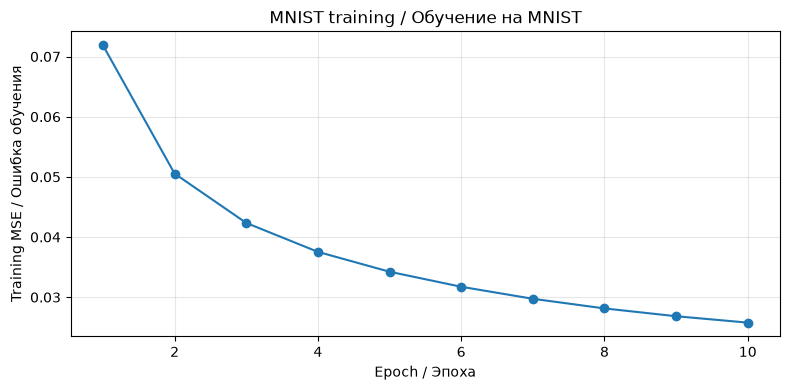

In [13]:
EPOCHS, BATCH_SIZE, LR = 10, 128, 0.05
with threadpool_limits(limits=1):
    history = train(
        model,
        x_train,
        y_train,
        criterion,
        optimizer,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        seed=SEED,
        verbose=True,
    )
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(history) + 1), history, marker="o")
ax.set(
    xlabel="Epoch / Эпоха",
    ylabel="Training MSE / Ошибка обучения",
    title="MNIST training / Обучение на MNIST",
)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "training_loss.png", dpi=150)
plt.show()

## 13. Test metrics and predictions / Тестовые метрики и предсказания

**EN.** Accuracy is the fraction of correctly predicted labels. Test MSE measures output-vector error and
is a different quantity from accuracy. The confusion matrix has true digits on rows and predictions on columns.
Its diagonal contains correct answers. The first 12 test images are shown without selecting only successful predictions.
The test set does not participate in parameter updates or hyperparameter selection.

**RU.** Accuracy — доля верно предсказанных цифр. Тестовая MSE измеряет ошибку выходных векторов и отличается от accuracy.
В матрице ошибок строки — правильные цифры, столбцы — прогнозы. На диагонали расположены правильные ответы.
Показаны первые 12 тестовых изображений без отбора только удачных предсказаний.
Тестовая выборка не участвует в обновлении параметров или подборе гиперпараметров.

Accuracy before / Точность до: 5.71%
Accuracy after / Точность после: 89.51%
Test MSE / Тестовая MSE: 0.024392
Accuracy per digit / Точность по цифрам: [0.9694 0.97   0.8401 0.8762 0.9053 0.8083 0.9415 0.8706 0.883  0.8731]


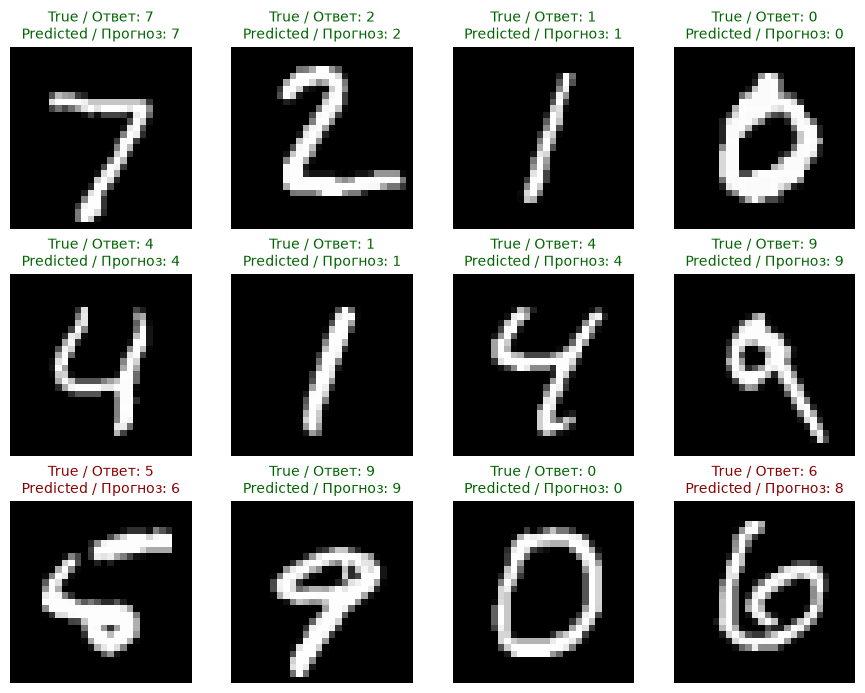

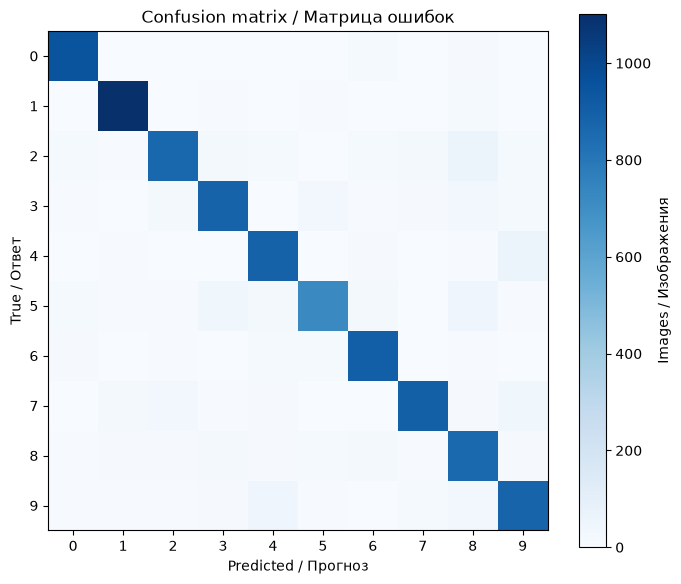

In [14]:
with threadpool_limits(limits=1):
    scores = predict(model, x_test)
predicted_labels = np.argmax(scores, axis=1)
accuracy_after = float(np.mean(predicted_labels == labels_test))
test_mse = criterion(scores, np.eye(10, dtype=np.float32)[labels_test])
confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (labels_test, predicted_labels), 1)
per_digit_accuracy = np.diag(confusion) / confusion.sum(axis=1)
print(f"Accuracy before / Точность до: {accuracy_before:.2%}")
print(f"Accuracy after / Точность после: {accuracy_after:.2%}")
print(f"Test MSE / Тестовая MSE: {test_mse:.6f}")
print("Accuracy per digit / Точность по цифрам:", np.round(per_digit_accuracy, 4))
fig, axes = plt.subplots(3, 4, figsize=(9, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"True / Ответ: {labels_test[i]}\nPredicted / Прогноз: {predicted_labels[i]}",
        color="darkgreen" if labels_test[i] == predicted_labels[i] else "darkred",
        fontsize=10,
    )
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "predictions.png", dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 6))
heatmap = ax.imshow(confusion, cmap="Blues")
ax.set(
    xlabel="Predicted / Прогноз",
    ylabel="True / Ответ",
    title="Confusion matrix / Матрица ошибок",
    xticks=range(10),
    yticks=range(10),
)
fig.colorbar(heatmap, ax=ax, label="Images / Изображения")
fig.tight_layout()
fig.savefig(OUT / "confusion_matrix.png", dpi=150)
plt.show()

## 14. Save, reload and compare / Сохранение, загрузка и сравнение

**EN.** Save the trained architecture and parameters, load a new model and compare all 10,000 test predictions.
Exact equality is checked with the same evaluation batch size. This verifies persistence rather than merely showing
that a file exists. Optimizer state and gradients are intentionally reset; this format saves an inference model.

**RU.** Сохраняем обученную структуру и параметры, загружаем новый объект и сравниваем прогнозы для всех 10 000 тестовых изображений.
Проверяем точное равенство при одинаковом размере порции оценки. Это проверяет восстановление модели, а не только наличие файла.
Состояние оптимизатора и градиенты сбрасываются; формат сохраняет модель для предсказаний.

In [15]:
model.save(OUT / "model.npz")
restored = Sequential.load(OUT / "model.npz")
with threadpool_limits(limits=1):
    restored_scores = predict(restored, x_test)
np.testing.assert_array_equal(restored_scores, scores)
metrics = {
    "dataset": "mnist_784",
    "version": 1,
    "seed": SEED,
    "train_samples": len(x_train),
    "test_samples": len(x_test),
    "architecture": [784, 32, 10],
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LR,
    "parameter_count": sum(p.value.size for p in model.parameters()),
    "accuracy_before": accuracy_before,
    "accuracy_after": accuracy_after,
    "test_mse": test_mse,
    "history": history,
    "per_digit_accuracy": per_digit_accuracy.tolist(),
    "confusion_matrix": confusion.tolist(),
    "restored_predictions_identical": True,
    "restore_max_absolute_difference": float(np.max(np.abs(restored_scores - scores))),
}
(OUT / "metrics.json").write_text(
    json.dumps(metrics, indent=2) + "\n", encoding="utf-8"
)
print(
    "All restored predictions are identical / Все прогнозы восстановленной модели совпали."
)
print("Saved results / Результаты сохранены:", OUT)

All restored predictions are identical / Все прогнозы восстановленной модели совпали.
Saved results / Результаты сохранены: C:\Users\USER\Documents\Aris Project\itmo-programming\course\lab3\results


## 15. Final UML and responsibility summary / Итоговая UML и ответственность классов

**EN.** Inheritance gives all transformations the same interface. Composition lets `Sequential` contain layers,
including another `Sequential`. A `Linear` owns two `Parameter` objects. SGD holds references to existing parameters,
so an optimizer update immediately changes model predictions. MSELoss has no trainable parameters.
`train` coordinates these objects without merging their responsibilities.

**RU.** Наследование даёт преобразованиям единый интерфейс. Композиция позволяет `Sequential` содержать слои,
в том числе другой `Sequential`. `Linear` владеет двумя объектами `Parameter`. SGD хранит ссылки на существующие
параметры, поэтому обновление сразу меняет прогнозы модели. MSELoss не содержит обучаемых параметров.
`train` организует взаимодействие объектов, сохраняя разделение их обязанностей.

The report also provides an editable Mermaid class diagram. / В отчёте также есть UML в формате Mermaid.

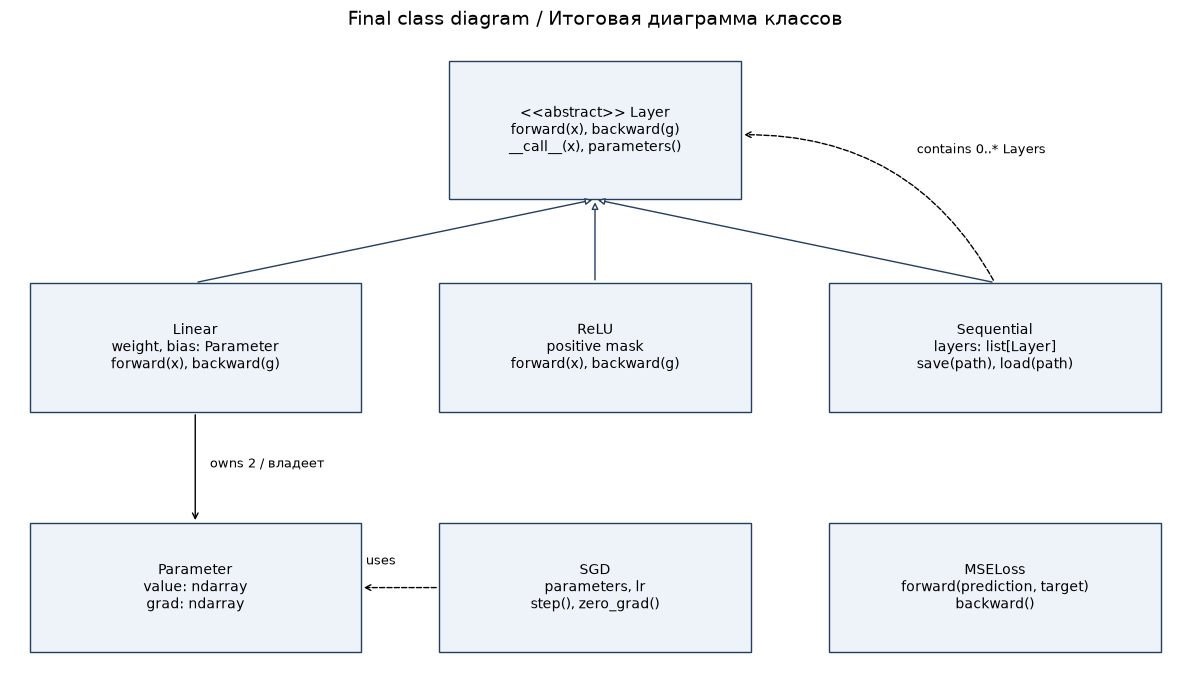

In [16]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(12, 7))
ax.set(xlim=(0, 12), ylim=(0, 7))
ax.axis("off")
boxes = {
    "Layer": (
        4.5,
        5.2,
        3,
        1.5,
        "<<abstract>> Layer\nforward(x), backward(g)\n__call__(x), parameters()",
    ),
    "Linear": (
        0.2,
        2.9,
        3.4,
        1.4,
        "Linear\nweight, bias: Parameter\nforward(x), backward(g)",
    ),
    "ReLU": (4.4, 2.9, 3.2, 1.4, "ReLU\npositive mask\nforward(x), backward(g)"),
    "Sequential": (
        8.4,
        2.9,
        3.4,
        1.4,
        "Sequential\nlayers: list[Layer]\nsave(path), load(path)",
    ),
    "Parameter": (0.2, 0.3, 3.4, 1.4, "Parameter\nvalue: ndarray\ngrad: ndarray"),
    "SGD": (4.4, 0.3, 3.2, 1.4, "SGD\nparameters, lr\nstep(), zero_grad()"),
    "MSELoss": (8.4, 0.3, 3.4, 1.4, "MSELoss\nforward(prediction, target)\nbackward()"),
}
for name, (left, bottom, width, height, text) in boxes.items():
    ax.add_patch(
        Rectangle(
            (left, bottom), width, height, facecolor="#eef3fa", edgecolor="#243e60"
        )
    )
    ax.text(
        left + width / 2,
        bottom + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=10,
    )
for x_position in [1.9, 6, 10.1]:
    ax.annotate(
        "",
        xy=(6, 5.2),
        xytext=(x_position, 4.3),
        arrowprops={"arrowstyle": "-|>", "facecolor": "white", "edgecolor": "#243e60"},
    )
ax.annotate("", xy=(1.9, 1.7), xytext=(1.9, 2.9), arrowprops={"arrowstyle": "->"})
ax.text(2.05, 2.3, "owns 2 / владеет", fontsize=9)
ax.annotate(
    "", xy=(3.6, 1), xytext=(4.4, 1), arrowprops={"arrowstyle": "->", "linestyle": "--"}
)
ax.text(3.65, 1.25, "uses", fontsize=9)
ax.annotate(
    "",
    xy=(7.5, 5.9),
    xytext=(10.1, 4.3),
    arrowprops={
        "arrowstyle": "->",
        "linestyle": "--",
        "connectionstyle": "arc3,rad=0.3",
    },
)
ax.text(9.3, 5.7, "contains 0..* Layers", fontsize=9)
ax.set_title("Final class diagram / Итоговая диаграмма классов", fontsize=14)
fig.tight_layout()
fig.savefig(OUT / "uml.png", dpi=150)
plt.show()

## 16. Defense checklist and limitations / Подготовка к защите и ограничения

**EN.** Be ready to explain the shape of every matrix, the derivative of MSE, why gradients accumulate,
why ReLU is needed, how the last batch is weighted, and why test data is separate. Compare the measured baseline and
trained accuracy above; do not describe outputs as probabilities. The full bilingual oral presentation, questions,
formulas and demonstration plan are in `DEFENSE_PREPARATION.md`; the source walkthrough is in `CODE_EXPLANATION.md`.

This educational library caches one forward pass per layer object. Use distinct layer instances at each model position:
reusing one instance twice would overwrite its cache. It does not implement automatic differentiation, GPU computation,
convolutions or shared-layer graphs. The saved model preserves supported nested architecture and parameter arrays.

**RU.** На защите объясните формы матриц, производную MSE, накопление градиентов, роль ReLU,
вес последней порции и разделение обучения и теста. Сравните измеренную точность до и после обучения;
не называйте выходы вероятностями. Полное выступление, вопросы, формулы и план демонстрации на двух языках —
в `DEFENSE_PREPARATION.md`, разбор исходного кода — в `CODE_EXPLANATION.md`.

Учебная библиотека хранит один прямой проход на объект слоя. Используйте отдельный экземпляр для каждой позиции:
повторное использование одного экземпляра перезапишет его кэш. Автодифференцирование, GPU, свёртки и графы
с разделяемыми слоями не реализованы. Файл модели сохраняет поддерживаемую вложенную структуру и массивы параметров.